# Linear regression in diabetes dataset

Let's explore the datasets that are included in this Python library. These datasets have been cleaned and formatted for use in ML algorithms.

First, we will load the diabetes dataset. Do this in the cell below by importing the datasets and then loading the dataset  to the `diabetes` variable using the `load_diabetes()` function ([documentation](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_diabetes.html)).

In [1]:
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
import pandas as pd
from sklearn.datasets import load_diabetes

diabetes = load_diabetes()

In [3]:
diabetes

{'data': array([[ 0.03807591,  0.05068012,  0.06169621, ..., -0.00259226,
          0.01990749, -0.01764613],
        [-0.00188202, -0.04464164, -0.05147406, ..., -0.03949338,
         -0.06833155, -0.09220405],
        [ 0.08529891,  0.05068012,  0.04445121, ..., -0.00259226,
          0.00286131, -0.02593034],
        ...,
        [ 0.04170844,  0.05068012, -0.01590626, ..., -0.01107952,
         -0.04688253,  0.01549073],
        [-0.04547248, -0.04464164,  0.03906215, ...,  0.02655962,
          0.04452873, -0.02593034],
        [-0.04547248, -0.04464164, -0.0730303 , ..., -0.03949338,
         -0.00422151,  0.00306441]], shape=(442, 10)),
 'target': array([151.,  75., 141., 206., 135.,  97., 138.,  63., 110., 310., 101.,
         69., 179., 185., 118., 171., 166., 144.,  97., 168.,  68.,  49.,
         68., 245., 184., 202., 137.,  85., 131., 283., 129.,  59., 341.,
         87.,  65., 102., 265., 276., 252.,  90., 100.,  55.,  61.,  92.,
        259.,  53., 190., 142.,  75., 142.

Let's explore this variable by looking at the different attributes (keys) of `diabetes`. Note that the `load_diabetes` function does not return dataframes. It returns you a Python dictionary.

In [4]:
diabetes.keys()

dict_keys(['data', 'target', 'frame', 'DESCR', 'feature_names', 'data_filename', 'target_filename', 'data_module'])

#### The next step is to read the description of the dataset. 

Print the description in the cell below using the `DESCR` attribute of the `diabetes` variable. Read the data description carefully to fully understand what each column represents.

*Hint: If your output is ill-formatted by displaying linebreaks as `\n`, it means you are not using the `print` function.*

In [5]:
print(diabetes['DESCR'])

.. _diabetes_dataset:

Diabetes dataset
----------------

Ten baseline variables, age, sex, body mass index, average blood
pressure, and six blood serum measurements were obtained for each of n =
442 diabetes patients, as well as the response of interest, a
quantitative measure of disease progression one year after baseline.

**Data Set Characteristics:**

:Number of Instances: 442

:Number of Attributes: First 10 columns are numeric predictive values

:Target: Column 11 is a quantitative measure of disease progression one year after baseline

:Attribute Information:
    - age     age in years
    - sex
    - bmi     body mass index
    - bp      average blood pressure
    - s1      tc, total serum cholesterol
    - s2      ldl, low-density lipoproteins
    - s3      hdl, high-density lipoproteins
    - s4      tch, total cholesterol / HDL
    - s5      ltg, possibly log of serum triglycerides level
    - s6      glu, blood sugar level

Note: Each of these 10 feature variables have bee

#### Based on the data description, answer the following questions:

1. How many attributes are there in the data? What do they mean?

1. What is the relation between `diabetes['data']` and `diabetes['target']`?

1. How many records are there in the data?

In [6]:
'''
Hay 10 atributos:
    - age     age in years
    - sex
    - bmi     body mass index
    - bp      average blood pressure
    - s1      tc, total serum cholesterol
    - s2      ldl, low-density lipoproteins
    - s3      hdl, high-density lipoproteins
    - s4      tch, total cholesterol / HDL
    - s5      ltg, possibly log of serum triglycerides level
    - s6      glu, blood sugar level
'''

'\nHay 10 atributos:\n    - age     age in years\n    - sex\n    - bmi     body mass index\n    - bp      average blood pressure\n    - s1      tc, total serum cholesterol\n    - s2      ldl, low-density lipoproteins\n    - s3      hdl, high-density lipoproteins\n    - s4      tch, total cholesterol / HDL\n    - s5      ltg, possibly log of serum triglycerides level\n    - s6      glu, blood sugar level\n'

In [7]:
#diabetes['data'] contiene las variables independientes (predictoras) tomadas al inicio del estudio, 
#mientras que diabetes['target'] es la variable dependiente (objetivo) que mide de forma cuantitativa la progresión de la enfermedad un año después.


In [8]:
#Hay un total de 442 registros (pacientes).

#### Now explore what are contained in the *data* portion as well as the *target* portion of `diabetes`. 

Scikit-learn typically takes in 2D numpy arrays as input (though pandas dataframes are also accepted). Inspect the shape of `data` and `target`. Confirm they are consistent with the data description.

In [9]:
print("Shape de data:", diabetes['data'].shape)
print("Shape de target:", diabetes['target'].shape)

Shape de data: (442, 10)
Shape de target: (442,)


## Building a regression model

The data have already been split to predictor (*data*) and response (*target*) variables. Given this information, we'll apply what we have previously learned about linear regression and apply the algorithm to the diabetes dataset.

#### In the cell below, import the `linear_model` class from `sklearn`. 

In [10]:
from sklearn import linear_model

#### Create a new instance of the linear regression model and assign the new instance to the variable `diabetes_model`.

In [11]:
diabetes_model = linear_model.LinearRegression()

#### Next, let's split the training and test data.

Define `diabetes_data_train`, `diabetes_target_train`, `diabetes_data_test`, and `diabetes_target_test`. Use the last 20 records for the test data and the rest for the training data.

In [12]:
diabetes_data_train = diabetes['data'][:-20]
diabetes_target_train = diabetes['target'][:-20]
diabetes_data_test = diabetes['data'][-20:]
diabetes_target_test = diabetes['target'][-20:]

Perform a brief exploratory analysis to investigate the conditions necessary for linear regression. This analysis will help you understand the distribution of the target variable and its correlations with other features.

Fit the training data and target to `diabetes_model`. Print the *intercept* and *coefficients* of the model.

In [13]:
#Creo el DataFrame
df = pd.DataFrame(diabetes['data'], columns=diabetes['feature_names'])
df['target'] = diabetes['target']

In [17]:
df.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


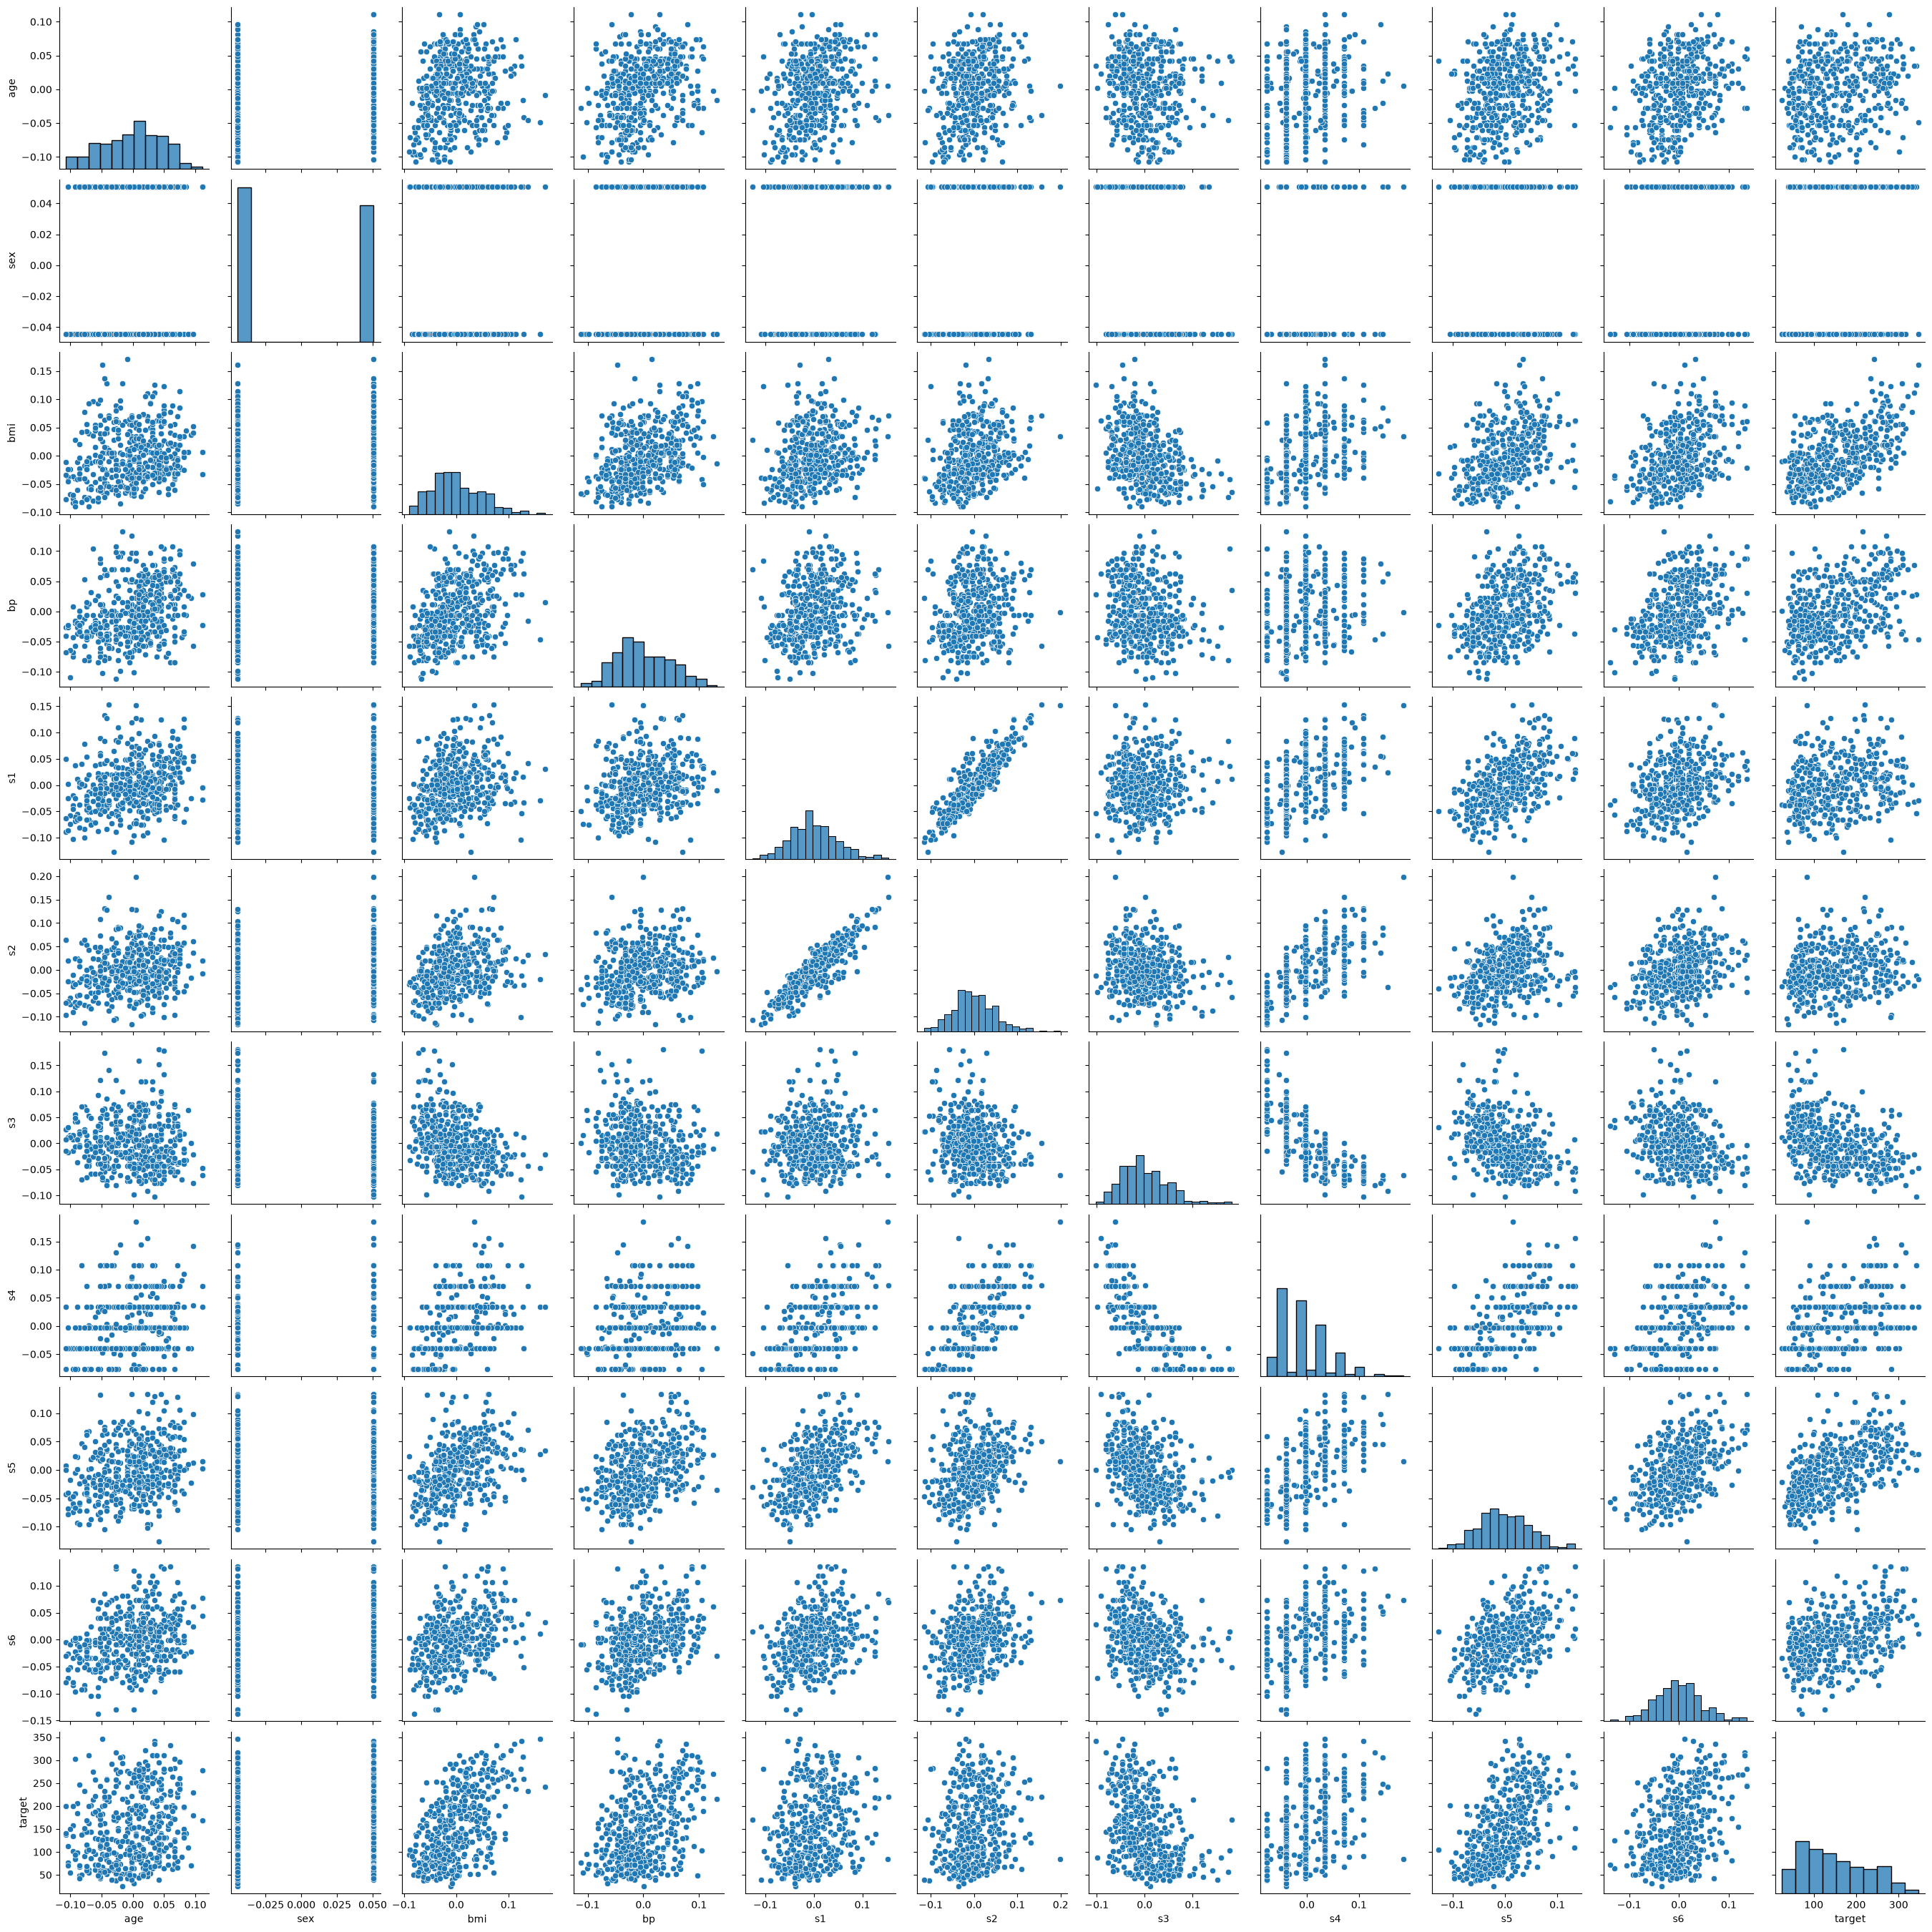

In [14]:
sns.pairplot(df)
plt.show()

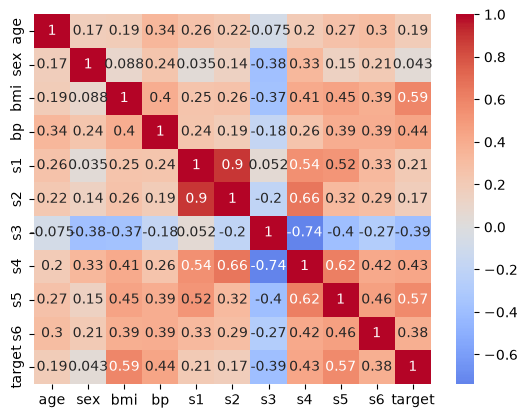

In [16]:
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm', center=0);

In [22]:
#Entreno el modelo con los datos de entrenamientode train
diabetes_model.fit(diabetes_data_train, diabetes_target_train)

#Imprimo el intercepto y los coeficientes
print("Intercepto:", diabetes_model.intercept_)   #intercepto: cuánto vale el target cuando todas las features valen cero. Ed la constante
print("Coeficientes:", diabetes_model.coef_)

Intercepto: 152.76429169049118
Coeficientes: [ 3.06094248e-01 -2.37635570e+02  5.10538048e+02  3.27729878e+02
 -8.14111926e+02  4.92799595e+02  1.02841240e+02  1.84603496e+02
  7.43509388e+02  7.60966464e+01]


#### Inspecting the results

From the outputs you should have seen:

- The intercept is a float number.
- The coefficients are an array containing 10 float numbers.

This is the linear regression model fitted to your training dataset.

#### Using your fitted linear regression model, predict the *y* of `diabetes_data_test`.

In [23]:
predicciones = diabetes_model.predict(diabetes_data_test)

#### Print your `diabetes_target_test` and compare with the prediction. 

In [36]:
comparacion = pd.DataFrame({
    'Valor Real': diabetes_target_test,
    'Predicción': predicciones.round(1)
})
comparacion


,Valor Real,Predicción
0,233.0,197.6
1,91.0,155.4
2,111.0,172.9
3,152.0,111.5
4,120.0,164.8
5,67.0,131.1
6,310.0,259.1
7,94.0,100.5
8,183.0,117.1
9,66.0,124.3


#### Is `diabetes_target_test` exactly the same as the model prediction? Use different error metrics

In [38]:
#No son iguales, calculo los errores. OJO en el TEST

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

print(f'MAE:', mean_absolute_error(diabetes_target_test, predicciones))
print(f'MSE:', mean_squared_error(diabetes_target_test, predicciones))
print(f'RMSE:', np.sqrt(mean_squared_error(diabetes_target_test, predicciones)))
print(f'R2 Score:', r2_score(diabetes_target_test, predicciones))


MAE: 36.60961865545879
MSE: 2004.5186863342096
RMSE: 44.77185149549
R2 Score: 0.585085427447195


#### Iterate with a new model to assess if any improvements can be made compared to the previous one. Consider reducing the number of variables or using `StandardScaler` to enhance model performance.

In [ ]:
#Selecciono las variables que más peso tienen, pero quito s2, ya que s2 y s1 el valor de correlación entre ellas es 0.9 (multicolinealidad)
features = ['s1', 's5', 'bmi', 'bp', 'sex']
X = df[features]
y = df['target']

In [27]:
#Hago el mismo split que antes (últimos 20 registros para test)
X_train, X_test = X[:-20], X[-20:]
y_train, y_test = y[:-20], y[-20:]

In [28]:
#Entreno el nuevo modelo solamente con las variables seleccionadas
modelo_2 = linear_model.LinearRegression()
modelo_2.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](5,)","[-216.75, 653.16, 598.02, 310.77,-142.11]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](5,)","['s1','s5','bmi','bp','sex']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,152.7
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,5
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(5)


In [ ]:
pip freeze   #Para ver las versiones que tienes

annotated-doc==0.0.5
annotated-types==0.8.0
anyio==4.15.1
argon2-cffi==25.1.0
argon2-cffi-bindings==26.1.0
arrow==1.4.0
asttokens==3.0.2
async-lru==2.3.0
attrs==26.1.0
babel==2.18.0
beautifulsoup4==4.15.0
bleach==6.4.0
blis==1.3.3
branca==0.8.2
catalogue==2.0.10
certifi==2026.7.22
cffi==2.1.1
charset-normalizer==3.5.1
click==8.5.0
cloudpathlib==0.26.0
cloudpickle==3.1.2
colorama==0.4.6
comm==0.2.3
confection==1.3.3
contourpy==1.4.0
cycler==0.12.1
cymem==2.0.13
debugpy==1.8.22
decorator==5.3.1
defusedxml==0.7.1
et_xmlfile==2.0.0
executing==2.2.1
fastjsonschema==2.22.2
folium==0.20.0
fonttools==4.67.0
formulaic==1.2.2
fqdn==1.5.1
future==1.0.0
geocoder==1.38.1
geographiclib==2.1
geopy==2.5.0
h11==0.16.0
httpcore==1.0.9
httpx==0.28.1
idna==3.20
interface_meta==2.0.1
ipykernel==7.3.0
ipython==9.17.1
ipython_pygments_lexers==1.1.1
isoduration==20.11.0
jedi==0.20.0
Jinja2==3.1.6
joblib==1.6.0
json5==0.15.0
jsonpointer==3.1.1
jsonschema==4.26.0
jsonschema-specifications==2025.9.1
jupyter-even

In [30]:
#Predicciones y métricas
predicciones_2 = modelo_2.predict(X_test)

print('MAE:', mean_absolute_error(y_test, predicciones_2))
print('MSE:', mean_squared_error(y_test, predicciones_2))
print('RMSE:', np.sqrt(mean_squared_error(y_test, predicciones_2)))
print('R2 Score:', r2_score(y_test, predicciones_2))

MAE: 35.43441681464385
MSE: 1869.667026882277
RMSE: 43.23964647036649
R2 Score: 0.6129983219594721


In [31]:
from sklearn.preprocessing import StandardScaler

#Split (últimos 20 para test, igual que antes)
features = ['s1', 's5', 'bmi', 'bp', 'sex']
X = df[features]
y = df['target']

X_train, X_test = X[:-20], X[-20:]
y_train, y_test = y[:-20], y[-20:]

#Escalo
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)   #aprende media y desviación del train
X_test_sc = scaler.transform(X_test)         #aplica los de train, sin volver a ajustar

#Modelo
modelo_3 = linear_model.LinearRegression()
modelo_3.fit(X_train_sc, y_train)

predicciones_3 = modelo_3.predict(X_test_sc)

print('MAE:', mean_absolute_error(y_test, predicciones_3))
print('MSE:', mean_squared_error(y_test, predicciones_3))
print('RMSE:', np.sqrt(mean_squared_error(y_test, predicciones_3)))
print('R2 Score:', r2_score(y_test, predicciones_3))

MAE: 35.43441681464385
MSE: 1869.6670268822768
RMSE: 43.23964647036649
R2 Score: 0.6129983219594721
